# 03 - Eksplorasi Dataset Kaggle (EDA)

**Dataset:** [`yaemico/judionline`](https://www.kaggle.com/datasets/yaemico/judionline) - komentar YouTube berbahasa Indonesia yang diberi label
`1` = promosi judi online, `0` = komentar normal.

Tujuan notebook ini: **memahami data sebelum melatih model** (notebook `02_training_model.ipynb`).

Isi:
1. Setup & load data
2. Gambaran umum (struktur, missing value, duplikat)
3. Memperbaiki kolom tanggal yang formatnya campur aduk
4. Distribusi label & kualitas label
5. Channel, video, dan author
6. Karakteristik teks per label (panjang, emoji, huruf "fancy", angka)
7. Kata, bigram, dan nama situs judi yang paling sering muncul
8. Pola template / spam
9. Tren waktu
10. Ringkasan temuan

> Bisa dijalankan langsung di Google Colab: *Runtime -> Run all*. Tidak perlu akun Kaggle karena dataset bersifat publik.

## 1. Setup & load data

In [1]:
# Library yang belum tersedia default di Colab
%pip install -q kagglehub emoji wordcloud nltk

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os
from collections import Counter

import numpy as np
import pandas as pd
import kagglehub
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import re
import unicodedata

import emoji
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOPWORDS_ID = set(stopwords.words("indonesian"))

# Emoji khusus YouTube berbentuk teks, mis. ":face-blue-smiling:" (menggantikan youtubeemoji.csv)
RE_YT_EMOJI = re.compile(r":[a-z0-9]+(?:-[a-z0-9]+)+:")
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION_HASHTAG = re.compile(r"[@#]\w+")
RE_NON_ALNUM = re.compile(r"[^0-9a-z\s]")
# Huruf yang dispasi untuk mengelabui filter: "p l u t o 8 8" -> "pluto88"
RE_SPACED = re.compile(r"\b(?:\w ){3,}\w\b")  # minimal 4 karakter, agar "1 2 m" tidak ikut

# Homoglif: huruf Cyrillic/Yunani yang bentuknya sama dengan huruf Latin.
# NFKC TIDAK mengubahnya (Cyrillic "a" tetap Cyrillic), jadi dipetakan manual.
HOMOGLYPH = {
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y",
    "х": "x", "к": "k", "м": "m", "т": "t", "н": "h", "в": "b",
    "і": "i", "ј": "j", "ѕ": "s", "ԁ": "d",
    "α": "a", "ο": "o", "ε": "e", "ι": "i", "κ": "k", "ν": "v",
    "ρ": "p", "τ": "t", "υ": "u", "χ": "x",
}
TABEL_HOMOGLYPH = str.maketrans(HOMOGLYPH)

# Token penanda trik penyamaran. Ditambahkan ke teks supaya TF-IDF bisa memakainya sebagai fitur.
SINYAL = {
    "xxfancy": "huruf/angka gaya (bold, italic, fullwidth, circled) yang dinormalisasi NFKC",
    "xxhomoglyph": "huruf Cyrillic/Yunani yang menyamar di dalam kata Latin",
    "xxspaced": "huruf yang dipisah spasi, mis. 'P L U T O 8 8'",
    "xxdecor": "simbol dekoratif non-ASCII selain emoji, mis. blok/bintang/aksara asing",
}


def obfuscation_signals(text):
    # Mendeteksi trik penyamaran dari teks ASLI, sebelum informasinya hilang oleh cleaning
    sinyal = set()
    if not isinstance(text, str):
        return sinyal
    for c in text:
        if c.isascii() or c.isspace():
            continue
        n = unicodedata.normalize("NFKC", c)
        if n.isascii():
            if n.isalnum():
                sinyal.add("xxfancy")
        elif c.lower() in HOMOGLYPH:
            continue  # dicek per kata di bawah
        elif (emoji.is_emoji(c) or unicodedata.category(c) in ("Mn", "Me", "Cf", "Sk")
              or unicodedata.name(c, "").startswith("LATIN")):
            continue
        else:
            sinyal.add("xxdecor")
    for kata in unicodedata.normalize("NFKC", text).lower().split():
        if any(c in HOMOGLYPH for c in kata) and any("a" <= c <= "z" for c in kata):
            sinyal.add("xxhomoglyph")
    return sinyal


def clean_text(text, remove_stopwords=True, add_signals=True):
    # Pipeline cleaning yang SAMA untuk training dan untuk data hasil scraping
    if not isinstance(text, str):
        return ""
    sinyal = obfuscation_signals(text) if add_signals else set()  # 0. catat trik penyamaran
    text = unicodedata.normalize("NFKC", text)        # 1. huruf "fancy" (Mathematical Bold dsb.) -> ASCII biasa
    text = emoji.replace_emoji(text, replace=" ")     # 2. hapus emoji unicode (termasuk bendera)
    text = RE_YT_EMOJI.sub(" ", text)                 # 3. hapus emoji khusus YouTube
    text = text.lower().translate(TABEL_HOMOGLYPH)    # 4. huruf kecil + homoglif -> Latin
    text = "".join(c for c in unicodedata.normalize("NFKD", text)
                   if not unicodedata.combining(c))   #    hapus aksen: cafe' -> cafe
    text = RE_URL.sub(" ", text)                      # 5. hapus URL
    text = RE_MENTION_HASHTAG.sub(" ", text)          # 6. hapus mention & hashtag
    text = RE_NON_ALNUM.sub(" ", text)                # 7. hapus tanda baca / simbol
    text = re.sub(r"\s+", " ", text).strip()          # 8. normalisasi spasi
    digabung = RE_SPACED.sub(lambda m: m.group().replace(" ", ""), text)  # 9. gabung huruf yang dispasi
    if add_signals and digabung != text:
        sinyal.add("xxspaced")
    tokens = digabung.split()
    if remove_stopwords:                              # 10. hapus stopword Bahasa Indonesia
        tokens = [t for t in tokens if t not in STOPWORDS_ID]
    return " ".join(tokens + sorted(sinyal))          # 11. tempel token sinyal di akhir

In [4]:
path = kagglehub.dataset_download("yaemico/judionline")
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
print("File:", csv_file)

df = pd.read_csv(csv_file)
df.head()

File: /home/drpoch/.cache/kagglehub/datasets/yaemico/judionline/versions/3/data_komentar_dengan_prediksi - data_komentar_dengan_prediksi(2).csv


,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


## 2. Gambaran umum

| Kolom | Arti |
|---|---|
| `video_id`, `title`, `channel_name` | video asal komentar |
| `tanggal` | waktu komentar (format campur, diperbaiki di bagian 3) |
| `author` | nama akun pengomentar |
| `komentar` | teks asli komentar |
| `label` | **target**: 1 = promosi judi, 0 = normal |
| `komentar_clean` | hasil cleaning versi pembuat dataset |
| `predicted_label` | prediksi model pembuat dataset (bukan ground truth, jangan dipakai sebagai fitur) |

In [5]:
print("Ukuran data :", df.shape)
print()
df.info()

Ukuran data : (10230, 9)

<class 'pandas.DataFrame'>
RangeIndex: 10230 entries, 0 to 10229
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   video_id         10230 non-null  str  
 1   title            10230 non-null  str  
 2   channel_name     10230 non-null  str  
 3   tanggal          10230 non-null  str  
 4   author           10230 non-null  str  
 5   komentar         10230 non-null  str  
 6   label            10230 non-null  int64
 7   komentar_clean   10230 non-null  str  
 8   predicted_label  10230 non-null  int64
dtypes: int64(2), str(7)
memory usage: 2.6 MB


In [6]:
ringkas = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "nilai_unik": df.nunique(),
})
ringkas

,tipe,missing,nilai_unik
video_id,str,0,32
title,str,0,32
channel_name,str,0,18
tanggal,str,0,7289
author,str,0,9267
komentar,str,0,9001
label,int64,0,2
komentar_clean,str,0,8903
predicted_label,int64,0,2


In [7]:
print(f"Jumlah author unik  : {df['author'].nunique():,}")
print(f"Jumlah channel unik : {df['channel_name'].nunique():,}")
print(f"Jumlah video unik   : {df['video_id'].nunique():,}")
print(f"Baris duplikat penuh            : {df.duplicated().sum():,}")
print(f"Duplikat teks komentar (persis) : {df['komentar'].duplicated().sum():,}")

Jumlah author unik  : 9,267
Jumlah channel unik : 18
Jumlah video unik   : 32
Baris duplikat penuh            : 0
Duplikat teks komentar (persis) : 1,229


## 3. Memperbaiki kolom `tanggal`

Kolom `tanggal` berisi dua format sekaligus:
- unix timestamp (milidetik/mikrodetik) yang rusak karena diberi titik ribuan, mis. `1.745.412.234.123.970`
- string ISO, mis. `2025-04-30 09:01:02+00:00`

Untuk format pertama, titik dibuang lalu 10 digit pertama dibaca sebagai detik unix.

In [8]:
def parse_tanggal(s):
    s = str(s).strip()
    if re.fullmatch(r"[\d.]+", s):
        digits = s.replace(".", "")
        return pd.to_datetime(int(digits[:10]), unit="s", utc=True)
    return pd.to_datetime(s, utc=True, errors="coerce")

df["format_tanggal"] = np.where(df["tanggal"].str.fullmatch(r"[\d.]+"), "unix bertitik", "ISO")
df["waktu"] = df["tanggal"].apply(parse_tanggal)

print(df["format_tanggal"].value_counts(), "\n")
print("Gagal di-parse :", df["waktu"].isna().sum())
print("Rentang waktu  :", df["waktu"].min(), "s/d", df["waktu"].max())
df[["tanggal", "format_tanggal", "waktu"]].sample(5, random_state=0)

format_tanggal
unix bertitik    7272
ISO              2958
Name: count, dtype: int64 

Gagal di-parse : 0
Rentang waktu  : 2025-02-06 07:05:31+00:00 s/d 2025-05-04 13:36:57+00:00


,tanggal,format_tanggal,waktu
6125,1.745.387.030.603.970,unix bertitik,2025-04-23 05:43:50+00:00
8745,173.882.554.098.906,unix bertitik,2025-02-06 07:05:40+00:00
39,1.739.946.323.623.560,unix bertitik,2025-02-19 06:25:23+00:00
5105,1.739.947.013.183.460,unix bertitik,2025-02-19 06:36:53+00:00
3380,2025-04-30 09:01:02+00:00,ISO,2025-04-30 09:01:02+00:00


## 4. Distribusi label & kualitas label

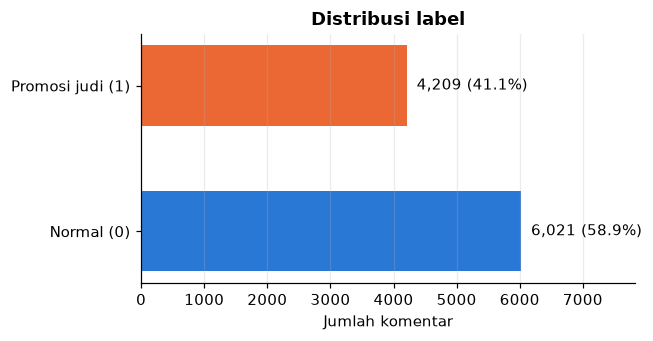

In [9]:
jumlah = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh([NAMA_LABEL[i] for i in jumlah.index], jumlah.values,
               color=[WARNA_LABEL[i] for i in jumlah.index], height=0.55)
for b, v in zip(bars, jumlah.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f"  {v:,} ({v / len(df):.1%})", va="center")
ax.set_xlabel("Jumlah komentar")
ax.set_title("Distribusi label")
ax.set_xlim(0, jumlah.max() * 1.3)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Data **tidak seimbang ringan** (~59% : 41%). Ini akan ditangani saat training (undersampling pada data latih saja).

Dataset juga menyertakan `predicted_label` dari model pembuatnya. Membandingkannya dengan `label` memberi gambaran seberapa sulit tugas ini.

Kesesuaian label vs predicted_label: 99.16%


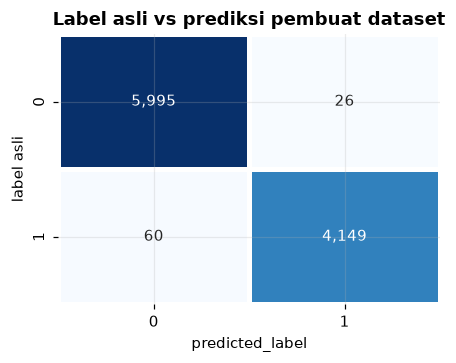

,komentar,label,predicted_label
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,0
426,@ jadilah top mantap is the best :face-blue-smiling:,0,1
481,kapan lagi wehde 2 juta modal 50k? ⭐ A L E X I S 1 7 ⭐ doang kayak nya wkwkwk,1,0
586,"Gue buka YouTube, yang direkomendasiin isinya PULAUWIN semua.",1,0
611,Layanannya di 𝘼X𝙇𝟩𝟽7juga oke banget! Gak ada masalah sama sekali!,1,0
655,meuni gacoor pisan iyeu ꗥ𝙈𝘼𝙉𝙐𝙏88ꗥ,1,0
898,Bener benar gelapppppp,0,1
970,ngopi muter digaruda hoki manteeb bat,1,0
1176,"Best, ini gokil banget sih🔥👍🏻",0,1
1465,puma speedcat bikin ngiler,0,1


In [10]:
ct = pd.crosstab(df["label"], df["predicted_label"], rownames=["label asli"], colnames=["predicted_label"])
print(f"Kesesuaian label vs predicted_label: {(df['label'] == df['predicted_label']).mean():.2%}")

fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
ax.set_title("Label asli vs prediksi pembuat dataset")
plt.tight_layout()
plt.show()

df.loc[df["label"] != df["predicted_label"], ["komentar", "label", "predicted_label"]].head(10)

## 5. Channel, video, dan author

In [11]:
per_channel = (df.groupby("channel_name")
                 .agg(komentar=("label", "size"), promosi=("label", "sum"), video=("video_id", "nunique"))
                 .assign(persen_promosi=lambda d: d["promosi"] / d["komentar"] * 100)
                 .sort_values("komentar", ascending=False))
per_channel.head(15)

,komentar,promosi,video,persen_promosi
channel_name,,,,
Garasi Drift,1951,588,4,30.138391
GadgetIn,1455,615,2,42.268041
Narasi Newsroom,1453,0,1,0.000000
Fitra Eri,1180,1036,4,87.796610
Pandji Pragiwaksono,837,130,1,15.531661
Motomobi,806,714,4,88.585608
Wakil Presiden Republik Indonesia,804,0,1,0.000000
Karbida FC,460,268,1,58.260870
Om Mobi,408,397,2,97.303922


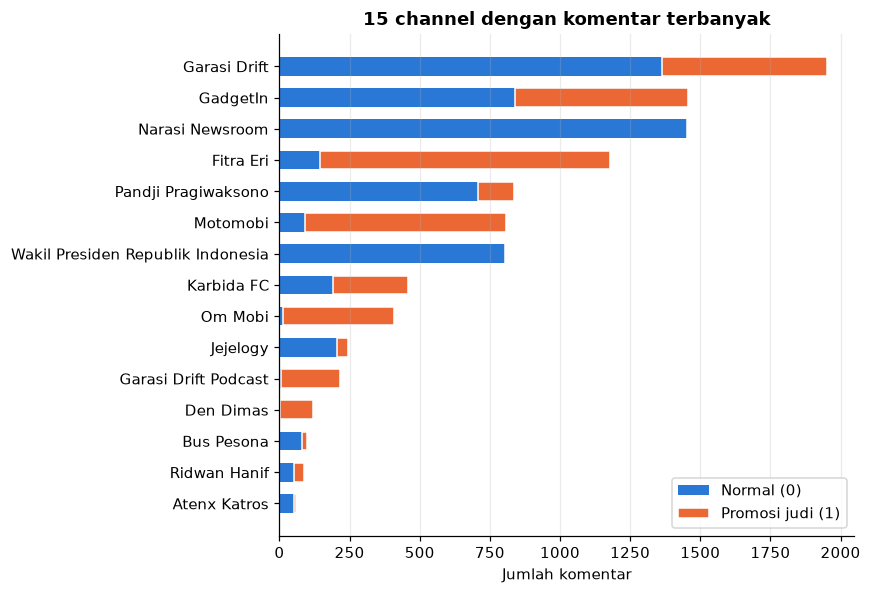

In [12]:
top = per_channel.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["komentar"] - top["promosi"], color=WARNA_LABEL[0], label=NAMA_LABEL[0], height=0.6)
ax.barh(top.index, top["promosi"], left=top["komentar"] - top["promosi"], color=WARNA_LABEL[1],
        label=NAMA_LABEL[1], height=0.6, edgecolor="white", linewidth=1)
ax.set_xlabel("Jumlah komentar")
ax.set_title("15 channel dengan komentar terbanyak")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [13]:
per_author = df.groupby("author").agg(komentar=("label", "size"), promosi=("label", "sum"))
print(f"Author yang menulis >1 komentar promosi : {(per_author['promosi'] > 1).sum():,}")
print(f"Author yang menulis promosi DAN normal  : {((per_author['promosi'] > 0) & (per_author['promosi'] < per_author['komentar'])).sum():,}")

# Handle YouTube otomatis biasanya berakhiran '-xxx' (3 karakter acak), sering dipakai akun bot
df["author_pola_otomatis"] = df["author"].str.contains(r"-[a-z0-9]{3}$", regex=True)
print()
print("Proporsi author berpola handle otomatis per label:")
print(df.groupby("label")["author_pola_otomatis"].mean().rename(NAMA_LABEL).map("{:.1%}".format))
per_author.sort_values("promosi", ascending=False).head(10)

Author yang menulis >1 komentar promosi : 181
Author yang menulis promosi DAN normal  : 12

Proporsi author berpola handle otomatis per label:
label
Normal (0)           5.9%
Promosi judi (1)    53.8%
Name: author_pola_otomatis, dtype: str


,komentar,promosi
author,,
MotorRacing-v8m,5,5
alarconJgillen-p9f,3,3
Rsabadoondi-w5c,3,3
aalambhatibhati3264,3,3
latuponogaluh,3,3
KancutBadak-h4v,3,3
GuillaumeMadara-v7q,3,3
ProgrammerJcui-o9o,3,3
PitcherS-n4h,3,3


## 6. Karakteristik teks per label

Fitur sederhana yang dihitung dari teks **asli** (`komentar`):
- `n_char`, `n_kata` - panjang komentar
- `n_emoji` - jumlah emoji
- `n_fancy` - jumlah huruf "fancy" (mis. huruf Mathematical Bold) yang berubah setelah normalisasi NFKC; trik umum untuk menghindari filter kata
- `ada_brand` - ada token huruf+angka seperti `pluto88`, `alexis17` (pola nama situs judi)

In [14]:
def n_fancy(text):
    return sum(1 for c in str(text) if ord(c) > 127 and unicodedata.normalize("NFKC", c) != c)

df["komentar_bersih"] = df["komentar"].apply(clean_text)
df["n_char"] = df["komentar"].str.len()
df["n_kata"] = df["komentar"].str.split().str.len()
df["n_emoji"] = df["komentar"].apply(emoji.emoji_count)
df["n_fancy"] = df["komentar"].apply(n_fancy)
df["ada_brand"] = df["komentar_bersih"].str.contains(r"\b[a-z]+\d{2,}\b", regex=True)

fitur = ["n_char", "n_kata", "n_emoji", "n_fancy", "ada_brand"]
df.groupby("label")[fitur].mean().rename(index=NAMA_LABEL).round(2)

,n_char,n_kata,n_emoji,n_fancy,ada_brand
label,,,,,
Normal (0),36.13,6.17,0.56,0.16,0.01
Promosi judi (1),45.94,8.10,0.18,2.57,0.66


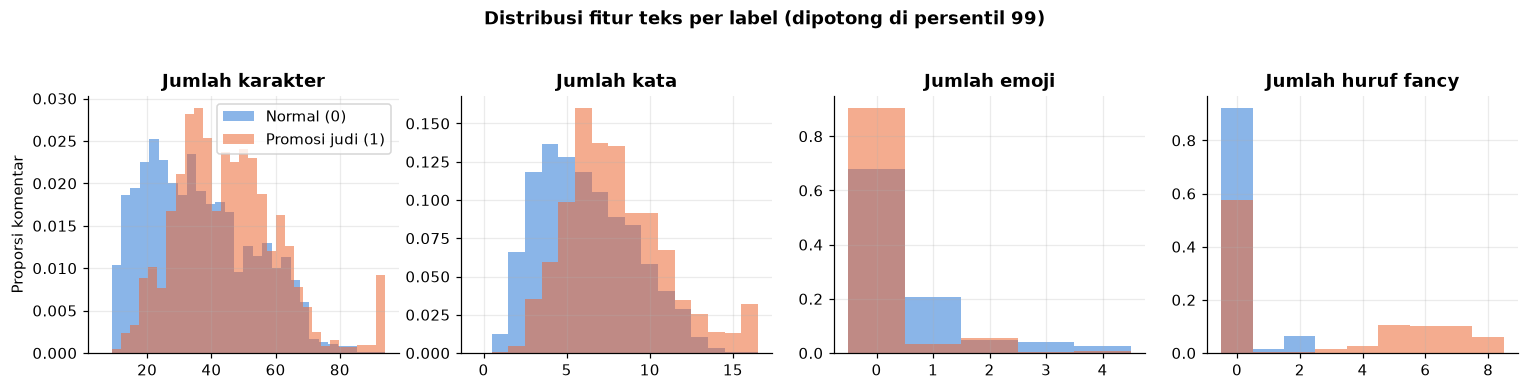

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (kol, judul) in zip(axes, [("n_char", "Jumlah karakter"), ("n_kata", "Jumlah kata"),
                                    ("n_emoji", "Jumlah emoji"), ("n_fancy", "Jumlah huruf fancy")]):
    batas = int(df[kol].quantile(0.99))
    bins = np.arange(0, batas + 2) - 0.5 if batas <= 30 else 30
    for lab in [0, 1]:
        data = df.loc[df["label"] == lab, kol].clip(upper=batas)
        # density=True -> proporsi, supaya kelas yang lebih besar tidak terlihat dominan
        ax.hist(data, bins=bins, density=True, alpha=0.55, color=WARNA_LABEL[lab], label=NAMA_LABEL[lab])
    ax.set_title(judul)
axes[0].set_ylabel("Proporsi komentar")
axes[0].legend()
plt.suptitle("Distribusi fitur teks per label (dipotong di persentil 99)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

In [16]:
print("Contoh efek normalisasi NFKC pada komentar promosi ber-huruf fancy:\n")
contoh = df[(df["label"] == 1) & (df["n_fancy"] > 0)].sample(5, random_state=1)
for _, r in contoh.iterrows():
    print("ASLI  :", r["komentar"])
    print("BERSIH:", r["komentar_bersih"])
    print()

Contoh efek normalisasi NFKC pada komentar promosi ber-huruf fancy:

ASLI  : orang kantor udh join 𝘼𝙇𝙀𝙓𝙄𝙎17
BERSIH: orang kantor udh join alexis17 xxfancy

ASLI  : Gak sabar buat main lagi di 𝘈𝐺𝐔𝑆𝐓𝑂𝙏𝘖, karena rezeki datang tak terduga!
BERSIH: gak sabar main agustoto rezeki terduga xxfancy

ASLI  : aer𝘖 88 menawarkan pendekatan berbeda keterlibatan daring .
BERSIH: aero 88 menawarkan pendekatan berbeda keterlibatan daring xxfancy

ASLI  : Salam ⭐𝐒𝐆𝐈𝟖𝟖! gampang Jepe ,Sehat selalu buat semuanya
BERSIH: salam sgi88 gampang jepe sehat xxfancy

ASLI  : depo , mekswin 𝘋 𝐸 𝙒 𝐴 𝐷 о 𝐑 a
BERSIH: depo mekswin dewadora xxfancy xxspaced



## 7. Kata, bigram, dan nama situs judi

Teks dibersihkan dengan fungsi `clean_text` yang **sama persis** dengan yang dipakai di notebook 01 (scraping) dan 02 (training).

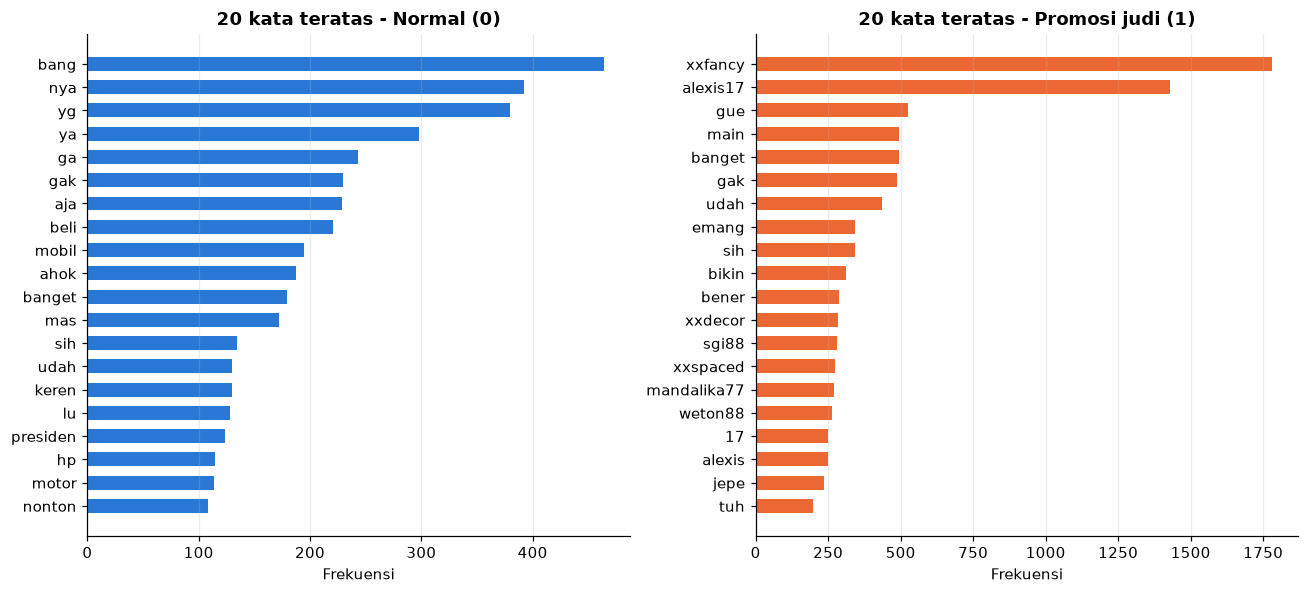

In [17]:
def top_tokens(series, n=20):
    return Counter(" ".join(series).split()).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, lab in zip(axes, [0, 1]):
    kata, frek = zip(*top_tokens(df.loc[df["label"] == lab, "komentar_bersih"]))
    ax.barh(kata[::-1], frek[::-1], color=WARNA_LABEL[lab], height=0.6)
    ax.set_title(f"20 kata teratas - {NAMA_LABEL[lab]}")
    ax.set_xlabel("Frekuensi")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [18]:
def top_bigram(series, n=15):
    cv = CountVectorizer(ngram_range=(2, 2), min_df=3)
    X = cv.fit_transform(series)
    frek = np.asarray(X.sum(axis=0)).ravel()
    idx = frek.argsort()[::-1][:n]
    return pd.Series(frek[idx], index=cv.get_feature_names_out()[idx])

pd.concat({NAMA_LABEL[lab]: top_bigram(df.loc[df["label"] == lab, "komentar_bersih"]).reset_index()
           .set_axis(["bigram", "frekuensi"], axis=1) for lab in [0, 1]}, axis=1)

Normal (0)               Promosi judi (1)          
              bigram frekuensi               bigram frekuensi
0        modif motor        42            alexis 17       248
1      langsung beli        25      xxdecor xxfancy       186
2           mas dipo        24             gue udah       155
3       garasi drift        24     xxfancy xxspaced       154
4       keren banget        23        main alexis17       149
5            om mobi        22         alexis17 tuh       145
6             11 100        19            emang gak       141
7          omon omon        19  xxfancy xxhomoglyph       138
8          mobil nya        19          bener bener       126
9        dislike nya        18        sgi88 xxfancy       123
10          otw beli        17         alexis17 gue       106
11  presiden prabowo        16          tujuh tujuh       102
12       bang pandji        15      weton88 xxfancy        88
13          the best        15        join alexis17        85
14      bikin konten        14      bilang alexis17        85

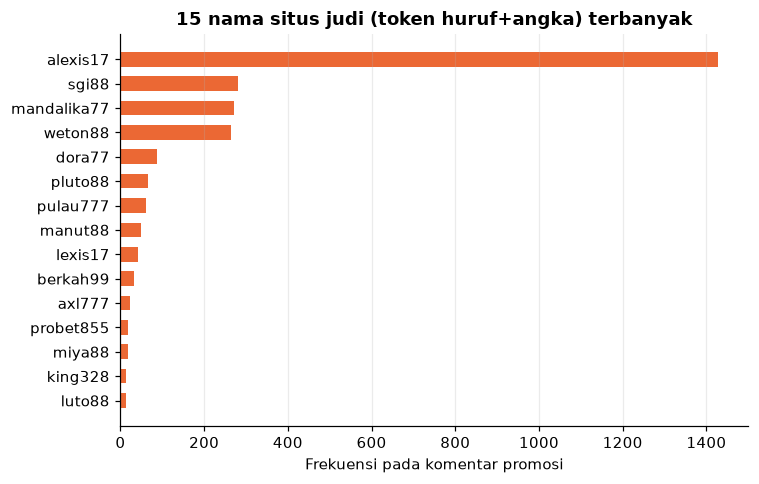

Komentar promosi yang memuat token brand : 65.6%
Komentar normal yang memuat token brand  : 1.0%


In [19]:
# Token huruf+angka (mis. pluto88, alexis17) adalah pola khas nama situs judi
brand = Counter(t for teks in df.loc[df["label"] == 1, "komentar_bersih"]
                for t in teks.split() if re.fullmatch(r"[a-z]+\d{2,}", t))
top_brand = pd.Series(dict(brand.most_common(15)))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_brand.index[::-1], top_brand.values[::-1], color=WARNA_LABEL[1], height=0.6)
ax.set_title("15 nama situs judi (token huruf+angka) terbanyak")
ax.set_xlabel("Frekuensi pada komentar promosi")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Komentar promosi yang memuat token brand : {df.loc[df['label'] == 1, 'ada_brand'].mean():.1%}")
print(f"Komentar normal yang memuat token brand  : {df.loc[df['label'] == 0, 'ada_brand'].mean():.1%}")

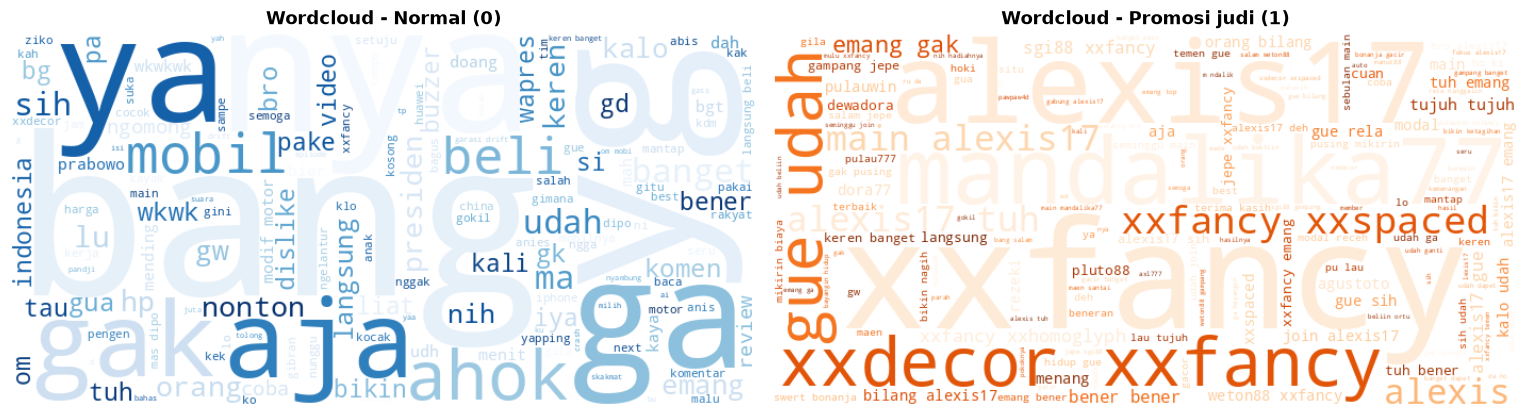

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, lab, cmap in zip(axes, [0, 1], ["Blues", "Oranges"]):
    teks = " ".join(df.loc[df["label"] == lab, "komentar_bersih"])
    wc = WordCloud(width=700, height=350, background_color="white", colormap=cmap,
                   max_words=150, random_state=42).generate(teks)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Wordcloud - {NAMA_LABEL[lab]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Pola template / spam

Bot promosi biasanya memakai **kalimat template** yang sama dan hanya mengganti nama situs.
Untuk melihatnya, token brand diganti `<brand>` lalu dihitung kalimat yang berulang.

In [21]:
df["template"] = df["komentar_bersih"].str.replace(r"\b[a-z]+\d{2,}\b", "<brand>", regex=True)

dup = df.groupby("label").agg(
    total=("template", "size"),
    teks_unik=("komentar_bersih", "nunique"),
    template_unik=("template", "nunique"),
).rename(index=NAMA_LABEL)
dup["persen_template_berulang"] = (1 - dup["template_unik"] / dup["total"]) * 100
display(dup.round(1))

df[df["label"] == 1]["template"].value_counts().head(10).to_frame("jumlah")

,total,teks_unik,template_unik,persen_template_berulang
label,,,,
Normal (0),6021,5937,5937,1.4
Promosi judi (1),4209,2695,2595,38.3


,jumlah
template,
semangat bosqu terbaik <brand> xxfancy,15
berkah rezeki berkat <brand> puji syukur xxfancy,13
yg tunggu2 <brand> xxfancy,13
cakep kali <brand> bravo xxfancy,13
kerennn contentnya bang cari situs <brand> xxfancy,13
gw demen gas <brand> wkwkwkww seru sering2 sih mah xxfancy,13
terima kasi rezekinya <brand> xxfancy,13
sukaaa bangettt <brand> xxfancy,12
busett cerahh banget <brand> encess koinya ngasih mulu xxfancy,11


## 9. Tren waktu

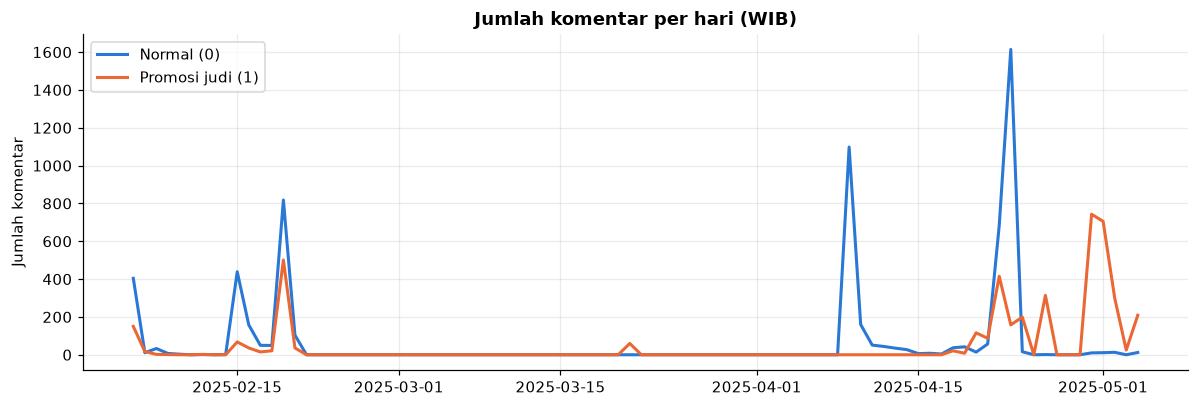

In [22]:
harian = (df.dropna(subset=["waktu"])
            .assign(tanggal_saja=lambda d: d["waktu"].dt.tz_convert("Asia/Jakarta").dt.date)
            .groupby(["tanggal_saja", "label"]).size().unstack(fill_value=0))
harian.index = pd.to_datetime(harian.index)
# Isi hari tanpa komentar dengan 0 agar garis tidak "melompati" tanggal kosong
harian = harian.reindex(pd.date_range(harian.index.min(), harian.index.max(), freq="D"), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.8))
for lab in [0, 1]:
    if lab in harian:
        ax.plot(harian.index, harian[lab], color=WARNA_LABEL[lab], lw=2, label=NAMA_LABEL[lab])
ax.set_title("Jumlah komentar per hari (WIB)")
ax.set_ylabel("Jumlah komentar")
ax.legend()
plt.tight_layout()
plt.show()

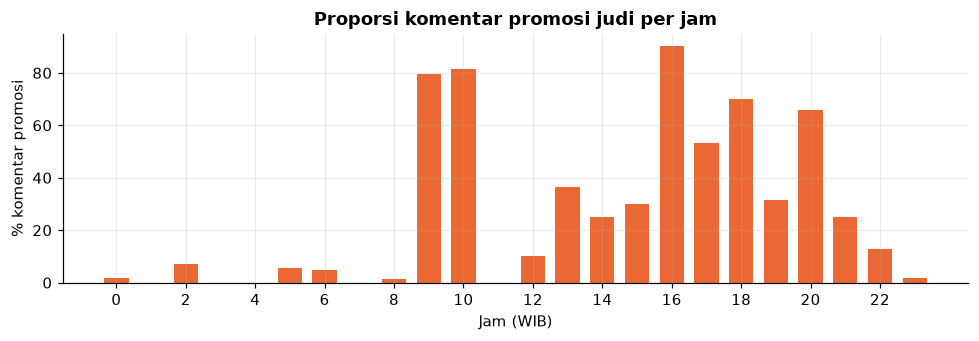

In [23]:
jam = df.dropna(subset=["waktu"]).assign(jam=lambda d: d["waktu"].dt.tz_convert("Asia/Jakarta").dt.hour)
proporsi_jam = jam.groupby("jam")["label"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(proporsi_jam.index, proporsi_jam.values, color=WARNA_LABEL[1], width=0.7)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("% komentar promosi")
ax.set_title("Proporsi komentar promosi judi per jam")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

## 10. Ringkasan temuan

In [24]:
p, n = df[df["label"] == 1], df[df["label"] == 0]
print(f"- {len(df):,} komentar dari {df['video_id'].nunique()} video / {df['channel_name'].nunique()} channel; "
      f"{df['label'].mean():.1%} berlabel promosi judi.")
print(f"- Tidak ada missing value; kolom tanggal perlu diparse ulang karena 2 format bercampur.")
print(f"- Kesesuaian label vs predicted_label bawaan dataset: {(df['label'] == df['predicted_label']).mean():.1%}.")
print(f"- Komentar promosi rata-rata {p['n_kata'].mean():.1f} kata vs normal {n['n_kata'].mean():.1f} kata.")
print(f"- Huruf fancy muncul di {(p['n_fancy'] > 0).mean():.1%} komentar promosi vs {(n['n_fancy'] > 0).mean():.1%} komentar normal.")
print(f"- Token brand (huruf+angka) ada di {p['ada_brand'].mean():.1%} komentar promosi vs {n['ada_brand'].mean():.1%} komentar normal.")
print(f"- Brand paling sering: {', '.join(top_brand.index[:5])}.")

- 10,230 komentar dari 32 video / 18 channel; 41.1% berlabel promosi judi.
- Tidak ada missing value; kolom tanggal perlu diparse ulang karena 2 format bercampur.
- Kesesuaian label vs predicted_label bawaan dataset: 99.2%.
- Komentar promosi rata-rata 8.1 kata vs normal 6.2 kata.
- Huruf fancy muncul di 42.3% komentar promosi vs 7.9% komentar normal.
- Token brand (huruf+angka) ada di 65.6% komentar promosi vs 1.0% komentar normal.
- Brand paling sering: alexis17, sgi88, mandalika77, weton88, dora77.


**Implikasi untuk training (notebook 02):**
1. Normalisasi Unicode (NFKC) **wajib** - tanpa itu `PLUTO88` versi huruf fancy dianggap token berbeda dan model mudah dikelabui.
2. Kolom `predicted_label` tidak boleh dipakai sebagai fitur (bocoran jawaban).
3. Banyak kalimat template yang berulang -> lakukan **deduplikasi sebelum split** agar kalimat yang sama tidak muncul di data latih dan data uji sekaligus (skor jadi terlalu optimis).
4. Label tidak seimbang ringan -> seimbangkan **hanya data latih**; data uji dibiarkan sesuai distribusi asli.
5. Proporsi promosi sangat berbeda antar channel (ada channel 0%, ada yang >95%) -> dataset ini mencerminkan cara pengumpulan data, bukan populasi YouTube. Jangan pakai nama channel/video sebagai fitur.
6. Nama situs judi sangat dominan -> model akan sangat bergantung pada token brand. Brand baru yang belum pernah dilihat akan lebih sulit dideteksi; ini keterbatasan yang perlu disebutkan.